In [1]:
%pip install pvlib scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


# AI for building energy: forecasting solar and demand to run a battery smarter
**Author:** Maduakor Uchechukwu David · MSc Energy for Solar Buildings and Cities

**Business question:** a commercial building in Grenoble has a 400 kWp rooftop PV plant and a 300 kWh battery. Can machine-learning (ML) forecasts of tomorrow's solar output and building demand reduce its electricity bill, compared with simple rules?

| # | Step | Method |
|---|---|---|
| 1 | Data | 2 years of hourly PVGIS weather, PV output with `pvlib`, office demand model |
| 2 | Forecasting | Day-ahead forecasts: persistence baseline vs gradient-boosted trees (`scikit-learn`) |
| 3 | Explainability | Permutation importance: which inputs drive each forecast |
| 4 | Battery control | Same battery, five control strategies |
| 5 | Business case | Annual cost, self-consumption, self-sufficiency, CO₂ |

Year 1 (2019) trains the models. Year 2 (2020) is kept unseen for testing, which is how a forecast is judged in a real deployment.

In [2]:
##libraries

import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"     # tells joblib how many CPU cores to use; stops the wmic warning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pvlib
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error

RNG = np.random.default_rng(7)     

## 1. Data
### 1.1 Site, PV system and weather
Grenoble (45.19 N, 5.72 E). Rooftop PV: **400 kWp**, 15° tilt facing south, 330 kW of inverters.
Hourly **in-plane irradiance**, air temperature and wind speed for **2019–2020** come from the PVGIS API (SARAH satellite data).
Unlike the TMY used in notebook 1, these are **real consecutive years**, which a forecast needs.

In [3]:
#A: site settings

SITE = dict(name="Grenoble, France", lat=45.19, lon=5.72, tz="Europe/Paris")
PV_KWP, INV_KW, TILT, AZIMUTH = 400, 330, 15, 180
YEARS = (2019, 2020)
location = pvlib.location.Location(SITE["lat"], SITE["lon"], tz="UTC", altitude=212)

In [4]:
#B: download two real years from PVGIS

raw, *_ = pvlib.iotools.get_pvgis_hourly(
    SITE["lat"], SITE["lon"], start=YEARS[0], end=YEARS[1],
    surface_tilt=TILT, surface_azimuth=AZIMUTH, components=True,
    map_variables=True, timeout=60)

weather = pd.DataFrame({
    "poa_global": raw[["poa_direct", "poa_sky_diffuse", "poa_ground_diffuse"]].sum(axis=1),
    "temp_air":   raw["temp_air"],
    "wind_speed": raw["wind_speed"]})
weather.index = weather.index.floor("h") + pd.Timedelta("30min")

print(f"{len(weather):,} hours from {weather.index[0]} to {weather.index[-1]}")
weather.describe().round(1)

17,544 hours from 2019-01-01 00:30:00+00:00 to 2020-12-31 23:30:00+00:00


,poa_global,temp_air,wind_speed
count,17544.0,17544.0,17544.0
mean,186.2,9.0,1.1
std,286.8,8.3,0.5
min,0.0,-11.5,0.0
25%,0.0,2.5,0.7
50%,0.0,8.6,1.0
75%,293.3,15.1,1.4
max,1059.2,31.6,3.7


In [5]:
#C: PV output

params = pvlib.temperature.TEMPERATURE_MODEL_PARAMETERS["sapm"]["close_mount_glass_glass"]
t_cell = pvlib.temperature.sapm_cell(weather["poa_global"], weather["temp_air"],
                                     weather["wind_speed"], **params)

pdc = pvlib.pvsystem.pvwatts_dc(weather["poa_global"], t_cell, PV_KWP, -0.0035) * 0.86   # 14 % losses
pv  = (pdc * 0.975).clip(lower=0, upper=INV_KW).rename("pv_kw")                         # inverter 97.5 %, 330 kW cap

annual = pv.sum() / len(YEARS)
print(f"Annual PV ≈ {annual/1000:,.0f} MWh  |  {annual/PV_KWP:,.0f} kWh/kWp  |  peak {pv.max():.0f} kW")

Annual PV ≈ 509 MWh  |  1,272 kWh/kWp  |  peak 308 kW


**Data check:** 17,544 hours (2019–2020, including the 2020 leap day), with no missing values.
- Mean in-plane irradiance 186 W/m² → about **1,630 kWh/m²/year** on the 15° plane.
- PV output: **≈509 MWh/year (1,272 kWh/kWp)**. The peak of 308 kW stays below the 330 kW inverter limit, so there is no clipping.
- Mean air temperature 9.0 °C and wind speed 1.1 m/s are **lower than Grenoble city measurements** (≈12–13 °C). PVGIS uses reanalysis data (ERA5) averaged over a grid cell that includes the surrounding mountains. This is a known limitation of the data, and it slightly underestimates cell temperature.

### 1.2 Building demand
Real smart-meter data for a specific building is private, so demand comes from a transparent **office-building model**:
- base load (servers, ventilation, standby) at all times
- occupancy on working days, 08:00–19:00, with ramps at 07:00 and 19:00
- **heating** below 15 °C and **cooling** above 22 °C
- French public holidays, plus random day-to-day variation

> To use real data instead, any hourly CSV with a timestamp and a kW column can replace `load` below, and the rest of the notebook runs unchanged.

In [6]:
#The demand model

LOAD_SCALE = 0.6      # building size relative to the default model

def office_load(index_utc, t_air, rng):
    local = index_utc.tz_convert(SITE["tz"])          # people work in local time, not UTC
    h, dow = local.hour, local.dayofweek               # hour 0–23, day 0 = Monday … 6 = Sunday
    holidays = {"01-01", "05-01", "05-08", "07-14", "08-15", "11-01", "11-11", "12-25"}
    workday  = (dow < 5) & ~pd.Index(local.strftime("%m-%d")).isin(holidays)
    occupied = workday & (h >= 8) & (h < 19)
    ramp     = workday & ((h == 7) | (h == 19))

    base    = 45.0                                                     # kW, always on
    occ     = np.where(occupied, 120.0, np.where(ramp, 55.0, 0.0))     # people, lights, computers
    heating = np.clip(15 - t_air, 0, None) * np.where(occupied, 6.0, 2.5)   # kW per °C below 15
    cooling = np.clip(t_air - 22, 0, None) * np.where(occupied, 9.0, 1.0)   # kW per °C above 22

    day_factor = np.repeat(rng.normal(1.0, 0.06, len(index_utc)//24 + 1), 24)[:len(index_utc)]
    noise      = rng.normal(0, 6, len(index_utc))
    return pd.Series((base + occ + heating + cooling) * day_factor + noise,
                     index=index_utc).clip(lower=20)

load = (office_load(weather.index, weather["temp_air"].values, RNG) * LOAD_SCALE).rename("load_kw")
df = pd.concat([pv, load, weather["temp_air"]], axis=1)

print(f"Annual demand ≈ {load.sum()/len(YEARS)/1000:,.0f} MWh  |  peak {load.max():.0f} kW  |  mean {load.mean():.0f} kW")
df.head()

Annual demand ≈ 588 MWh  |  peak 200 kW  |  mean 67 kW


,pv_kw,load_kw,temp_air
time,,,
2019-01-01 00:30:00+00:00,0.0,52.850612,-2.04
2019-01-01 01:30:00+00:00,0.0,45.701031,-2.27
2019-01-01 02:30:00+00:00,0.0,54.291828,-2.37
2019-01-01 03:30:00+00:00,0.0,47.486622,-2.28
2019-01-01 04:30:00+00:00,0.0,53.844410,-2.18


**Results:** annual demand ≈ **588 MWh** (mean 67 kW, peak 200 kW), against ≈509 MWh of PV.
On an annual basis, PV could cover about 87 % of the demand, but only if the energy could be used at the right time.

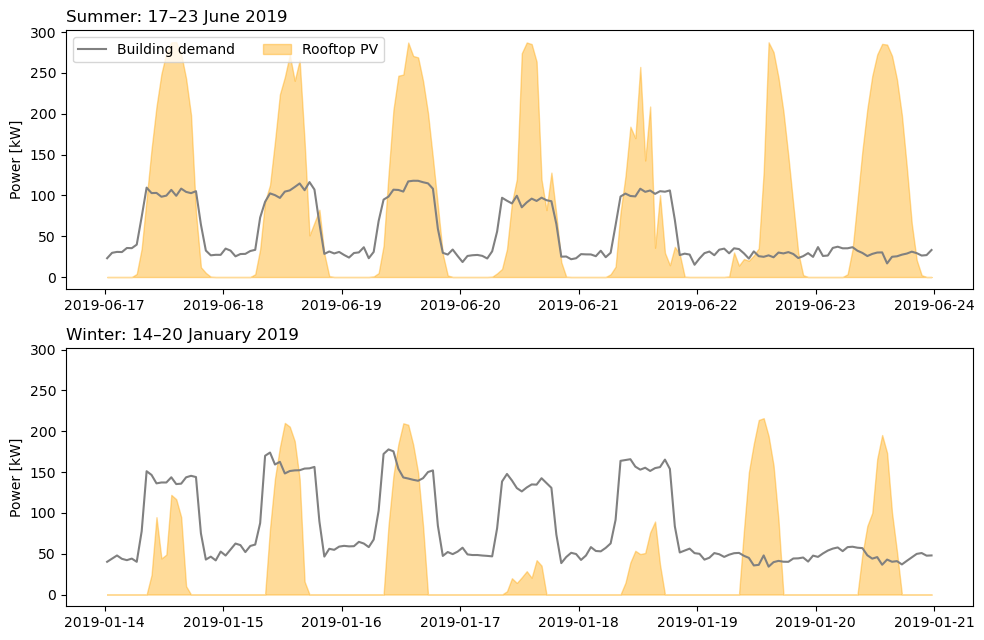

In [7]:
# Summer vs winter week (both Monday → Sunday, same y-scale)


weeks = {"Summer: 17–23 June 2019":   ("2019-06-17", "2019-06-23"),
         "Winter: 14–20 January 2019": ("2019-01-14", "2019-01-20")}

fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharey=True)
for ax, (title, (start, end)) in zip(axes, weeks.items()):
    w = df.tz_convert(SITE["tz"]).loc[start:end]
    ax.plot(w.index, w["load_kw"], color="grey", lw=1.5, label="Building demand")
    ax.fill_between(w.index, 0, w["pv_kw"], color="orange", alpha=0.4, label="Rooftop PV")
    ax.set_title(title, loc="left"); ax.set_ylabel("Power [kW]")
axes[0].legend(loc="upper left", ncol=2)
plt.tight_layout(); plt.show()

**Interpretation**
- **Summer:** PV peaks (≈285 kW) are **2.5× the weekday demand** (≈100–115 kW). Most of the midday energy is surplus, and at the weekend, when demand drops to ≈30 kW, almost all PV is exported for a low price.
- **Winter:** demand is **higher** (≈140–175 kW on weekdays, ≈45–60 kW at night) because of heating, while PV is **lower and much more variable**: ≈210 kW on clear days (15, 16 January) and almost nothing on cloudy days (17, 18 January).
- The two sunniest winter days (19–20 January) fall on a **weekend**, when the office is empty, so the energy is wasted.

→ **Mismatch in time, not in quantity.** A battery can move summer midday surplus to the evening and buy cheap night energy in winter. To decide *how much* to buy each night, it needs to know tomorrow's PV and demand. That is the role of the forecasts in Section 2.

Why model demand instead of using real data?

Smart-meter data from a real building is private. I built a transparent model with base load, occupancy, heating, cooling and holidays, so every assumption is visible. The notebook is built so a real hourly CSV can replace it without changing the rest of the code.

## 2. Day-ahead forecasting
At midnight the energy manager must plan tomorrow's battery use, so it needs **24-hour forecasts** of PV output and demand.

- **Weather forecast:** a real system would use a numerical weather prediction (NWP). Here the observed weather is degraded with realistic random errors (≈20 % on irradiance, ≈1.5 °C on temperature), so the models never see the true future.
- **Baseline: persistence.** "Tomorrow = today at the same hour." It is simple and surprisingly hard to beat, so any AI model must be compared against it.
- **ML model: gradient-boosted trees** (`HistGradientBoostingRegressor`), using calendar features, forecast weather, clear-sky irradiance (physics) and yesterday's value.

In [8]:
# Forecast = truth × random error (a stand-in for a real weather forecast)

poa_fc = weather["poa_global"] * RNG.lognormal(0, 0.20, len(df))
t_fc   = weather["temp_air"] + RNG.normal(0, 1.5, len(df))

# Clear-sky irradiance on the PV plane: what the panels would get with no clouds (pure physics)
solpos = location.get_solarposition(df.index)
cs     = location.get_clearsky(df.index, solar_position=solpos)
cs_poa = pvlib.irradiance.get_total_irradiance(
    TILT, AZIMUTH, solpos["apparent_zenith"], solpos["azimuth"],
    cs["dni"], cs["ghi"], cs["dhi"])["poa_global"].fillna(0)

print(f"Clear-sky max: {cs_poa.max():.0f} W/m²  |  Real max: {weather['poa_global'].max():.0f} W/m²")

Clear-sky max: 947 W/m²  |  Real max: 1059 W/m²


In [9]:
# Features and train/test split

local = df.index.tz_convert(SITE["tz"])

X = pd.DataFrame({
    "hour_sin": np.sin(2*np.pi*local.hour/24),      "hour_cos": np.cos(2*np.pi*local.hour/24),
    "doy_sin":  np.sin(2*np.pi*local.dayofyear/365), "doy_cos":  np.cos(2*np.pi*local.dayofyear/365),
    "weekday":  (local.dayofweek < 5).astype(int),   "dow":      local.dayofweek,
    "poa_forecast": poa_fc.values, "clearsky_poa": cs_poa.values, "temp_forecast": t_fc.values,
    "pv_yesterday":   df["pv_kw"].shift(24).values,
    "load_yesterday": df["load_kw"].shift(24).values,
}, index=df.index)

train = (local.year == YEARS[0]) & X.notna().all(axis=1)    # 2019, without the first day (no "yesterday")
test  =  local.year == YEARS[1]                              # 2020, never seen in training
print(f"Training hours: {train.sum():,} (2019) | Test hours: {test.sum():,} (2020)")
X.head(30).tail(6).round(2)

Training hours: 8,735 (2019) | Test hours: 8,784 (2020)


,hour_sin,hour_cos,doy_sin,doy_cos,weekday,dow,poa_forecast,clearsky_poa,temp_forecast,pv_yesterday,load_yesterday
time,,,,,,,,,,,
2019-01-02 00:30:00+00:00,0.26,0.97,0.03,1.0,1,2,0.0,0.0,-2.04,0.0,52.85
2019-01-02 01:30:00+00:00,0.50,0.87,0.03,1.0,1,2,0.0,0.0,0.28,0.0,45.70
2019-01-02 02:30:00+00:00,0.71,0.71,0.03,1.0,1,2,0.0,0.0,-0.31,0.0,54.29
2019-01-02 03:30:00+00:00,0.87,0.50,0.03,1.0,1,2,0.0,0.0,-0.57,0.0,47.49
2019-01-02 04:30:00+00:00,0.97,0.26,0.03,1.0,1,2,0.0,0.0,0.19,0.0,53.84
2019-01-02 05:30:00+00:00,1.00,0.00,0.03,1.0,1,2,0.0,0.0,-2.21,0.0,52.60


In [10]:
#train models and compare performance

FEATURES = {
    "pv_kw":   ["hour_sin", "hour_cos", "doy_sin", "doy_cos", "poa_forecast", "clearsky_poa", "temp_forecast", "pv_yesterday"],
    "load_kw": ["hour_sin", "hour_cos", "doy_sin", "doy_cos", "weekday", "dow", "temp_forecast", "load_yesterday"],
}
models, preds, rows = {}, {}, []

for target, feats in FEATURES.items():
    m = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, random_state=0)
    m.fit(X.loc[train, feats], df.loc[train, target])          # LEARN on 2019
    models[target] = m

    y      = df.loc[test, target]                               # truth in 2020
    y_ml   = pd.Series(m.predict(X.loc[test, feats]), index=y.index).clip(lower=0)
    if target == "pv_kw":
        y_ml = y_ml.where(X.loc[test, "clearsky_poa"] > 0, 0)  # no PV at night
    y_pers = X.loc[test, target.replace("_kw", "_yesterday")]   # persistence

    preds[target] = pd.DataFrame({"actual": y, "persistence": y_pers, "ml": y_ml})
    for name, yhat in [("Persistence", y_pers), ("Gradient boosting", y_ml)]:
        rmse = mean_squared_error(y, yhat) ** 0.5
        rows.append([target.replace("_kw", "").upper(), name,
                     mean_absolute_error(y, yhat), rmse, 100 * rmse / y.mean()])

metrics = pd.DataFrame(rows, columns=["Forecast", "Model", "MAE [kW]", "RMSE [kW]", "nRMSE [%]"])
rmse_tab = metrics.pivot(index="Forecast", columns="Model", values="RMSE [kW]")
skill = 100 * (1 - rmse_tab["Gradient boosting"] / rmse_tab["Persistence"])
display(metrics.round(1))
print("Skill vs persistence:", {k: f"{v:.0f} %" for k, v in skill.items()})

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

,Forecast,Model,MAE [kW],RMSE [kW],nRMSE [%]
0,PV,Persistence,19.8,45.9,79.0
1,PV,Gradient boosting,5.4,11.9,20.5
2,LOAD,Persistence,18.6,33.5,50.6
3,LOAD,Gradient boosting,6.4,10.8,16.4


Skill vs persistence: {'LOAD': '68 %', 'PV': '74 %'}


**Results on the unseen year (2020)**
- **PV:** gradient boosting cuts the RMSE from 45.9 to **11.9 kW** (nRMSE 79 % → 20.5 %), a **74 % skill** over persistence.
- **Demand:** RMSE drops from 33.5 to **10.8 kW** (nRMSE 51 % → 16.4 %), a **68 % skill**.
- Persistence fails on the **weather changes** (a sunny day after a cloudy one) for PV, and on **Mondays and holidays** for demand, because it copies the previous day. The ML model uses the weather forecast and the calendar.

**Caution:** these skills are optimistic. The "forecast" weather is the real weather plus independent random noise, and the demand comes from a model with the same structure the ML model learns. With real weather forecasts and real meter data, expect a skill of about 30–50 % for PV.

saying/identifying the caution.Its good to know the limits of your own results.

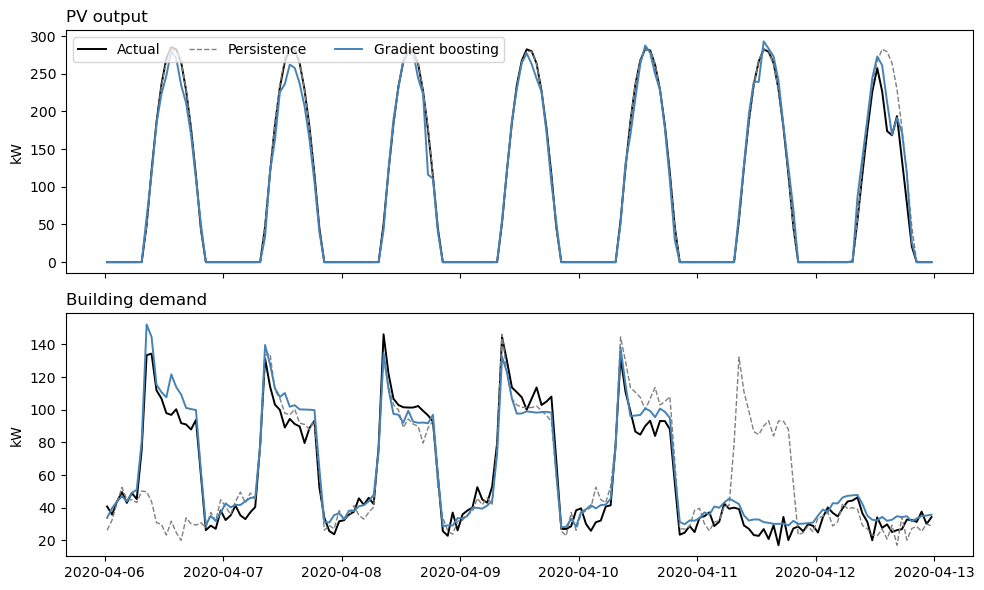

In [11]:
#one test week

wk = slice("2020-04-06", "2020-04-12")     # Monday → Sunday, in the unseen year

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, (target, label) in zip(axes, [("pv_kw", "PV output"), ("load_kw", "Building demand")]):
    p = preds[target].tz_convert(SITE["tz"]).loc[wk]
    ax.plot(p.index, p["actual"], color="black", lw=1.4, label="Actual")
    ax.plot(p.index, p["persistence"], color="grey", ls="--", lw=1, label="Persistence")
    ax.plot(p.index, p["ml"], color="steelblue", lw=1.4, label="Gradient boosting")
    ax.set_ylabel("kW"); ax.set_title(label, loc="left")
axes[0].legend(ncol=3, loc="upper left")
plt.tight_layout(); plt.show()

**Interpretation (test week 6–12 April 2020, never seen in training)**
- **PV:** most days are clear, so persistence works well. On **Sunday 12 April** it predicts a full clear-sky curve (copied from Saturday) and misses the clouds. The ML model follows the dips, because it uses the weather forecast.
- **Demand:** persistence fails twice:
  - **Monday 6 April:** it copies Sunday and predicts a low, flat day, so it misses the whole working day.
  - **Saturday 11 April:** it copies Friday and predicts a full working day (≈130 kW) for an empty building.
- The ML model gets both right, because it knows the day of the week. It slightly overestimates some weekday afternoons (≈+10 kW), which is normal day-to-day variation it cannot know in advance.

→ For a battery, these errors matter: a persistence plan on Saturday would buy night energy for a demand that never comes.

> **Section 2 summary:** Two day-ahead forecasts were trained on 2019 and tested on the unseen year 2020. Gradient boosting beats the persistence baseline by **74 % (PV)** and **68 % (demand)** in RMSE, mainly because it uses weather forecasts and calendar information. These skills are optimistic, because the forecast weather is simulated, but the ranking of the methods is robust.

Why compare with persistence?

"Persistence costs nothing and is surprisingly accurate for stable weather and regular buildings. If an AI model can't beat it, it isn't worth deploying. Reporting the skill against persistence is the standard way to show that a forecast adds value."

## 3. Explainability: what drives each forecast?
An ML model is a "black box" unless we check what it relies on.
**Permutation importance:** shuffle one input at a time on the test year and measure how much the error (RMSE) grows.
- Large increase → the model depends on that input.
- Near zero → the input is ignored.
This checks that the model learned **physics and behaviour** (sun, weather, working days), not noise.

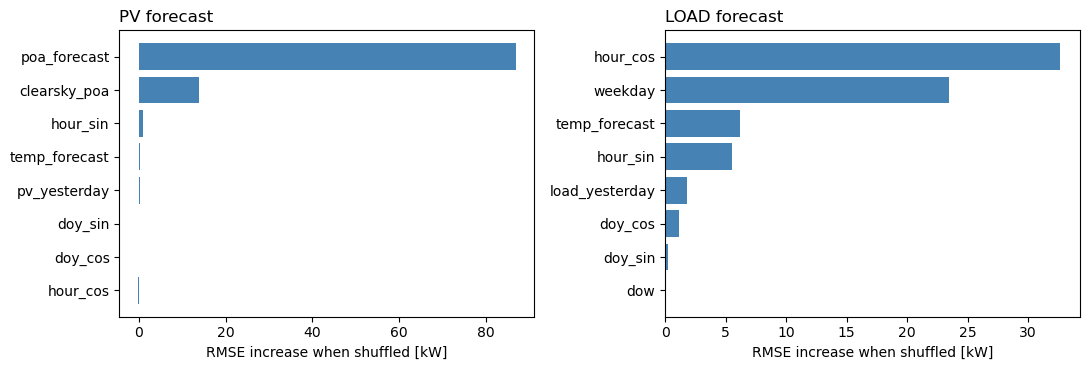

In [12]:
#permutation importance

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

for ax, (target, feats) in zip(axes, FEATURES.items()):
    sample = X.loc[test, feats].sample(2000, random_state=0)       # 2,000 random test hours (faster)
    r = permutation_importance(models[target], sample, df.loc[sample.index, target],
                               n_repeats=5, random_state=0,
                               scoring="neg_root_mean_squared_error")
    imp = pd.Series(r.importances_mean, index=feats).sort_values()
    ax.barh(imp.index, imp.values, color="steelblue")
    ax.set_title(f"{target.replace('_kw', '').upper()} forecast", loc="left")
    ax.set_xlabel("RMSE increase when shuffled [kW]")

plt.tight_layout(); plt.show()

**Interpretation**
- **PV:** the model relies almost entirely on `poa_forecast` (+87 kW RMSE when shuffled), then on `clearsky_poa` (+14 kW). Yesterday's PV and the calendar add almost nothing. This is the physics we expect: tomorrow's PV is set by tomorrow's sun and clouds, not by today's output.
- **Demand:** the time of day (`hour_cos` +33 kW, `hour_sin` +6 kW) and **working day vs weekend** (`weekday` +23 kW) dominate, followed by temperature (+6 kW, heating and cooling). This matches how an office building behaves.
- `dow` (day 0–6) gets ~0 because `weekday` already carries the same information: the model only needs "working day or not". `load_yesterday` adds little, which explains why persistence performs badly.

In [13]:
#what is physics worth?

# Retrain the PV model WITHOUT the clear-sky input, and compare
feats_no_cs = [f for f in FEATURES["pv_kw"] if f != "clearsky_poa"]
m2 = HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, random_state=0)
m2.fit(X.loc[train, feats_no_cs], df.loc[train, "pv_kw"])

y     = df.loc[test, "pv_kw"]
y_no  = pd.Series(m2.predict(X.loc[test, feats_no_cs]), index=y.index).clip(lower=0)
rmse_with = mean_squared_error(y, preds["pv_kw"]["ml"]) ** 0.5
rmse_no   = mean_squared_error(y, y_no) ** 0.5

print(f"PV RMSE with clear-sky physics: {rmse_with:.1f} kW | without: {rmse_no:.1f} kW "
      f"→ {100*(rmse_no/rmse_with - 1):+.0f} % error without physics")

PV RMSE with clear-sky physics: 11.9 kW | without: 12.2 kW → +2 % error without physics


**Ablation:** removing clear-sky irradiance raises the PV RMSE only from 11.9 to 12.2 kW (+2 %).
Permutation importance (14 kW) and ablation (+2 %) answer different questions:
- *Permutation:* how much does **this trained model** depend on the input? A lot.
- *Ablation:* can a **retrained model** do without it? Almost: clear-sky irradiance is a function of hour and day-of-year, so the model rebuilds it from those features.

→ The physics input is redundant here because of the large training set. It becomes more valuable with less data, or with a real weather forecast that is less accurate than `poa_forecast`.

> **Section 3 summary:** Permutation importance confirms that both models learned the expected drivers: forecast irradiance for PV, and time of day, working days and temperature for demand. An ablation test shows that the clear-sky physics feature adds only 2 % accuracy here, because the model can rebuild it from calendar features. The behaviour is consistent with physics, so the model can be trusted for battery control.

How do you know your AI model isn't a black box?

I used permutation importance to check which inputs drive each forecast. PV depends mainly on forecast irradiance, and demand on the hour, working days and temperature, which matches the physics and occupancy. I also ran an ablation test. It showed that correlated features can compensate for each other, so I don't read a single importance score as the whole story

## 4. Battery control: does a better forecast save money?
**Battery:** 300 kWh, 150 kW, 92 % round-trip efficiency, kept between 10 % and 100 % charge.
**Tariff (illustrative, French-style):** peak hours 06:00–22:00 at €0.25/kWh, off-peak at €0.16/kWh, surplus PV sold at €0.04/kWh.

Five ways to run the same battery:
1. **Solar charging only:** charge from PV surplus and discharge at peak price. No forecast.
2. **Always fill at night:** as 1, plus buy cheap off-peak energy every night until the battery is full. No forecast, so it often buys energy the sun would have supplied for free.
3. **Persistence forecast:** at midnight, plan tomorrow's night purchase assuming tomorrow = today.
4. **ML forecast:** the same plan using the gradient-boosting forecasts.
5. **Perfect forecast:** the same plan with tomorrow's true values. This is the ceiling any forecast could reach.

**The value of forecasting** is the cost gap between strategy 2 and strategies 3–5.

In [14]:
#battery and tariff settings

CAP, PMAX, SOC_MIN   = 300.0, 150.0, 0.10      # kWh, kW, minimum charge (10 %)
ETA_C, ETA_D         = 0.96, 0.96               # charge × discharge = 0.92 round trip
P_PEAK, P_OFF, P_EXP = 0.25, 0.16, 0.04         # €/kWh
CO2_GRID = 0.056      # kg CO2/kWh: assumed French grid average (check the ADEME value)

In [15]:
#the battery simulator

def run_battery(pv_s, load_s, plan_pv=None, plan_load=None, always_fill=False):
    """Hour-by-hour battery simulation. With plan_* given, buys off-peak energy at night
    to cover tomorrow's expected peak-hour deficit."""
    loc_idx = pv_s.index.tz_convert(SITE["tz"])
    peak = (loc_idx.hour >= 6) & (loc_idx.hour < 22)
    soc = target_soc = SOC_MIN * CAP
    out = []

    for i, (t, p, l) in enumerate(zip(loc_idx, pv_s.values, load_s.values)):
        # 1) at midnight: decide how full the battery should be before morning
        if t.hour == 0:
            if always_fill:
                target_soc = CAP
            elif plan_pv is not None:
                day = slice(i, i + 24)
                pp, ll, pk = plan_pv.values[day], plan_load.values[day], peak[day]
                deficit = np.clip(ll - pp, 0, None)[pk].sum()        # expected shortfall at peak price
                surplus = np.clip(pp - ll, 0, None).sum() * ETA_C     # what the sun will refill for free
                need = max(0.0, min(deficit / ETA_D, CAP) - surplus)
                target_soc = min(CAP, SOC_MIN * CAP + need)

        # 2) every hour: decide what the battery does
        net = p - l
        charge = discharge = grid_charge = 0.0
        if net > 0:                                     # PV surplus → charge
            charge = min(net, PMAX, (CAP - soc) / ETA_C)
        elif peak[i]:                                   # deficit at peak price → discharge
            discharge = min(-net, PMAX, (soc - SOC_MIN * CAP) * ETA_D)
        elif (plan_pv is not None or always_fill) and t.hour < 6 and soc < target_soc:   #  00:00–06:00 only, after the midnight plan
            grid_charge = min(PMAX, (target_soc - soc) / ETA_C)

        soc += (charge + grid_charge) * ETA_C - discharge / ETA_D
        grid_import = max(0.0, l - p - discharge) + grid_charge
        grid_export = max(0.0, p - l - charge)
        out.append((grid_import, grid_export, soc, peak[i]))

    return pd.DataFrame(out, columns=["import_kw", "export_kw", "soc_kwh", "peak"], index=pv_s.index)

In [16]:
#run the 7 cases and compare

def kpis(name, sim, pv_s, load_s):
    cost = (sim.import_kw * np.where(sim.peak, P_PEAK, P_OFF)).sum() - sim.export_kw.sum() * P_EXP
    pv_used = pv_s.sum() - sim.export_kw.sum()
    return {"Strategy": name,
            "Grid import [MWh]":    sim.import_kw.sum() / 1000,
            "Self-consumption [%]": np.nan if name.startswith("No PV") else 100 * pv_used / pv_s.sum(),
            "Self-sufficiency [%]": 100 * (1 - sim.import_kw.sum() / load_s.sum()),
            "Annual cost [k€]":     cost / 1000,
            "CO2 [t]":              sim.import_kw.sum() * CO2_GRID / 1000}

pv_t, load_t = df.loc[test, "pv_kw"], df.loc[test, "load_kw"]     # test year 2020
peak_t = (pv_t.index.tz_convert(SITE["tz"]).hour >= 6) & (pv_t.index.tz_convert(SITE["tz"]).hour < 22)

sims = {
    "No PV, no battery": pd.DataFrame({"import_kw": load_t, "export_kw": 0.0, "soc_kwh": 0.0, "peak": peak_t}),
    "PV only":           pd.DataFrame({"import_kw": (load_t - pv_t).clip(lower=0),
                                       "export_kw": (pv_t - load_t).clip(lower=0), "soc_kwh": 0.0, "peak": peak_t}),
    "Battery: solar charging only":  run_battery(pv_t, load_t),
    "Battery: always fill at night": run_battery(pv_t, load_t, always_fill=True),
    "Battery: persistence forecast": run_battery(pv_t, load_t, preds["pv_kw"]["persistence"], preds["load_kw"]["persistence"]),
    "Battery: ML forecast":          run_battery(pv_t, load_t, preds["pv_kw"]["ml"], preds["load_kw"]["ml"]),
    "Battery: perfect forecast":     run_battery(pv_t, load_t, pv_t, load_t),
}
results = pd.DataFrame([kpis(k, v, pv_t, load_t) for k, v in sims.items()]).set_index("Strategy")
results["Saving vs no PV [k€]"] = results.loc["No PV, no battery", "Annual cost [k€]"] - results["Annual cost [k€]"]
results.round(1)

,Grid import [MWh],Self-consumption [%],Self-sufficiency [%],Annual cost [k€],CO2 [t],Saving vs no PV [k€]
Strategy,,,,,,
"No PV, no battery",581.4,NaN,0.0,135.1,32.6,0.0
PV only,315.2,52.1,45.8,58.7,17.6,76.3
Battery: solar charging only,257.7,64.3,55.7,46.8,14.4,88.2
Battery: always fill at night,278.9,61.0,52.0,45.4,15.6,89.7
Battery: persistence forecast,262.1,63.9,54.9,45.3,14.7,89.7
Battery: ML forecast,259.7,64.3,55.3,45.0,14.5,90.0
Battery: perfect forecast,259.7,64.3,55.3,45.0,14.5,90.1


**Results (test year 2020)**
- **PV alone** cuts the bill from 135.1 to **58.7 k€** (−57 %): it brings by far the largest gain.
- **The battery** adds ≈**12–14 k€/year** on top, by moving midday surplus to peak hours.
- **Always fill at night** is cheap (45.4 k€), but it buys grid energy the sun would have supplied: self-sufficiency falls to 52 % and CO₂ rises to 15.6 t.
- **ML forecast:** **45.0 k€**, the same as a perfect forecast, with 55.3 % self-sufficiency and 14.5 t CO₂.
  → It is **as cheap as blind night charging *and* as clean as solar-only charging**: the best of both.
- The value of forecasting in cost alone is small: **0.3 k€/year** for ML, 0.1 for persistence, 0.4 for a perfect forecast. The ML model captures ≈75 % of what is achievable.

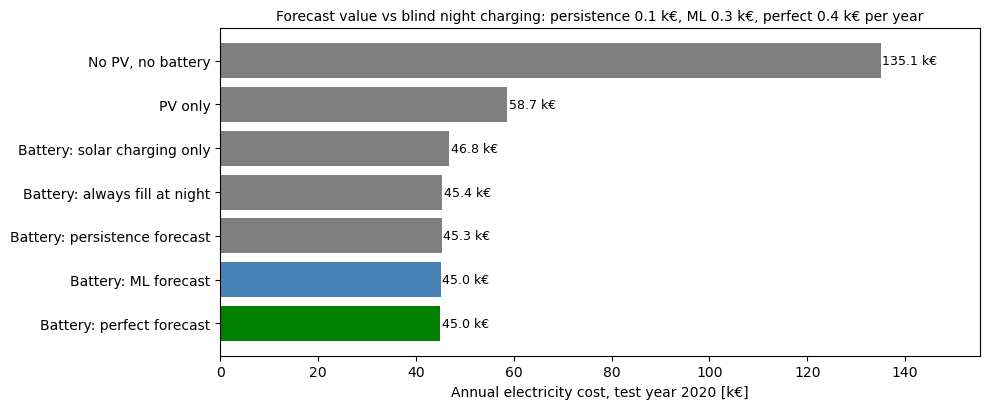

In [17]:
#cost chart

c = results["Annual cost [k€]"]
ref = c["Battery: always fill at night"]
gain = {k: ref - c[f"Battery: {k} forecast"] for k in ["persistence", "ML", "perfect"]}

fig, ax = plt.subplots(figsize=(10, 4.2))
order = results.index[::-1]
colors = ["green" if "perfect" in s else "steelblue" if "ML" in s else "grey" for s in order]
ax.barh(order, c[order], color=colors)
for y, v in enumerate(c[order]):
    ax.text(v + 0.3, y, f"{v:,.1f} k€", va="center", fontsize=9)
ax.set_xlabel("Annual electricity cost, test year 2020 [k€]")
ax.set_xlim(0, c.max() * 1.15)
ax.set_title(f"Forecast value vs blind night charging: persistence {gain['persistence']:.1f} k€, "
             f"ML {gain['ML']:.1f} k€, perfect {gain['perfect']:.1f} k€ per year", fontsize=10)
plt.tight_layout(); plt.show()

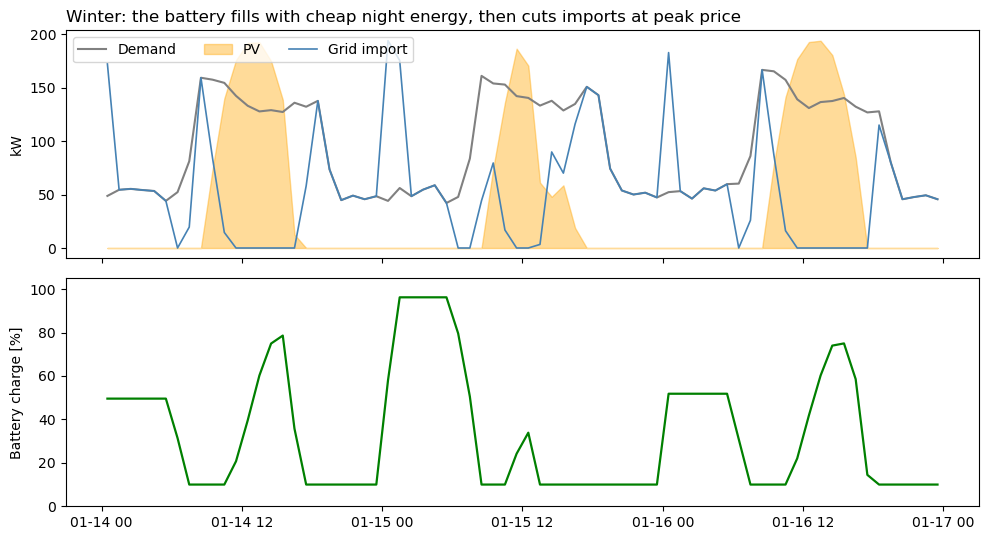

In [18]:
#3 winter days with the ML-controlled battery

d = slice("2020-01-14", "2020-01-16")
sim = sims["Battery: ML forecast"].tz_convert(SITE["tz"]).loc[d]
pp, ll = pv_t.tz_convert(SITE["tz"]).loc[d], load_t.tz_convert(SITE["tz"]).loc[d]

fig, ax = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
ax[0].plot(ll.index, ll, color="grey", label="Demand")
ax[0].fill_between(pp.index, 0, pp, color="orange", alpha=0.4, label="PV")
ax[0].plot(sim.index, sim["import_kw"], color="steelblue", lw=1.2, label="Grid import")
ax[0].set_ylabel("kW"); ax[0].legend(ncol=3, loc="upper left")
ax[1].plot(sim.index, sim["soc_kwh"] / CAP * 100, color="green", lw=1.6)
ax[1].set_ylabel("Battery charge [%]"); ax[1].set_ylim(0, 105)
ax[0].set_title("Winter: the battery fills with cheap night energy, then cuts imports at peak price", loc="left")
plt.tight_layout(); plt.show()

**Interpretation:** the battery now charges only **after midnight** (00:00–06:00), once tomorrow's plan is known.
- **15 Jan:** the plan expects little PV, so it fills to ≈96 % and covers the morning peak.
- **16 Jan:** it expects a sunny day, so it charges only to ≈52 %. The battery is empty by ≈09:00 and the building imports at peak price until the PV arrives.
→ The rule balances energy **over the whole day** but ignores the **order of the hours**: the morning deficit comes before the midday surplus.

**Debugging note:** an earlier version charged from 22:00 using the previous day's plan. Fixing it raised the cost slightly (44.6 → 45.0 k€), because the bug was hiding this weakness of the planning rule.

> **Section 4 summary:** On the unseen year, PV + battery cuts the electricity bill from 135 to ≈45 k€. ML-forecast control matches the perfect-forecast cost and achieves the cost of blind night charging with 1.1 t less CO₂ and 3 points more self-sufficiency. The pure monetary value of forecasting is small (0.3 k€/yr) with this tariff gap (€0.09/kWh) and battery size. The main remaining loss comes from the **simple planning rule**, not from the forecast. An hour-by-hour optimiser (linear programming) is the next improvement.

So is AI forecasting worth it here?

In cost terms only a little, about 0.3 k€ a year, because the gap between peak and off-peak prices is small. The real benefit is that it reaches the lowest cost without buying unnecessary grid energy, so it also gives lower CO₂ and higher self-sufficiency. I also found that the remaining loss comes from my planning rule, not the forecast, so the next step is an optimiser rather than a better model.

## 5. Summary for a decision-maker
The key figures from Sections 1–4 in one table, plus the results exported as CSV files for reports.

In [19]:
#key figures table + CSV export

from pathlib import Path
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)          # create the folder if it doesn't exist

r, c = results, results["Annual cost [k€]"]
gb = metrics[metrics["Model"] == "Gradient boosting"].set_index("Forecast")

key = pd.DataFrame([
    ["System",       "PV / battery",                    f"{PV_KWP} kWp  /  {CAP:.0f} kWh, {PMAX:.0f} kW"],
    ["Data",         "Weather",                         "PVGIS hourly 2019–2020 (train 2019, test 2020)"],
    ["Forecast",     "PV: nRMSE / skill",               f"{gb.loc['PV', 'nRMSE [%]']:.0f} %  /  {skill['PV']:.0f} %"],
    ["Forecast",     "Demand: nRMSE / skill",           f"{gb.loc['LOAD', 'nRMSE [%]']:.0f} %  /  {skill['LOAD']:.0f} %"],
    ["Cost",         "No PV → PV only",                 f"{c.iloc[0]:.1f} → {c.iloc[1]:.1f} k€/yr"],
    ["Cost",         "PV + ML-controlled battery",      f"{c['Battery: ML forecast']:.1f} k€/yr"],
    ["Value",        "Forecasting vs blind charging",   f"persistence {gain['persistence']:.1f} · ML {gain['ML']:.1f} · perfect {gain['perfect']:.1f} k€/yr"],
    ["Self-suff.",   "PV only → ML battery",            f"{r['Self-sufficiency [%]'].iloc[1]:.0f} % → {r.loc['Battery: ML forecast', 'Self-sufficiency [%]']:.0f} %"],
    ["CO₂",          "Blind night charging → ML",       f"{r.loc['Battery: always fill at night', 'CO2 [t]']:.1f} → {r.loc['Battery: ML forecast', 'CO2 [t]']:.1f} t/yr"],
], columns=["Topic", "Indicator", "Result"])

results.round(2).to_csv(OUT / "battery_strategies.csv")
metrics.round(2).to_csv(OUT / "forecast_metrics.csv", index=False)
print("Saved: outputs/battery_strategies.csv, outputs/forecast_metrics.csv")
key.set_index("Topic")

Saved: outputs/battery_strategies.csv, outputs/forecast_metrics.csv


,Indicator,Result
Topic,,
System,PV / battery,"400 kWp / 300 kWh, 150 kW"
Data,Weather,"PVGIS hourly 2019–2020 (train 2019, test 2020)"
Forecast,PV: nRMSE / skill,21 % / 74 %
Forecast,Demand: nRMSE / skill,16 % / 68 %
Cost,No PV → PV only,135.1 → 58.7 k€/yr
Cost,PV + ML-controlled battery,45.0 k€/yr
Value,Forecasting vs blind charging,persistence 0.1 · ML 0.3 · perfect 0.4 k€/yr
Self-suff.,PV only → ML battery,46 % → 55 %
CO₂,Blind night charging → ML,15.6 → 14.5 t/yr


## Conclusion
| Question | Answer |
|---|---|
| Can ML forecast tomorrow's PV and demand? | **Yes:** nRMSE 20.5 % (PV) and 16.4 % (demand), i.e. 74 % and 68 % better than persistence |
| Does the model behave physically? | **Yes:** PV is driven by forecast irradiance, demand by hour, working days and temperature |
| What saves the most money? | **PV itself** (−57 % of the bill), then the battery (≈−12–14 k€/yr) |
| What does the forecast add? | The lowest cost (45.0 k€, equal to a perfect forecast) **without** buying unnecessary grid energy: −1.1 t CO₂ and +3 points of self-sufficiency vs blind night charging |

## Limitations and next steps
- **Demand is modelled, not measured.** Next step: real smart-meter data (e.g. an open dataset).
- **Weather forecast error is simulated.** Next step: archived numerical weather forecasts (e.g. Open-Meteo historical forecast API). Expect lower skill.
- **The planning rule ignores the order of the hours.** Next step: a linear-programming optimiser (`scipy.optimize.linprog` or `pulp`) to find the optimal schedule each day.
- **The tariff is illustrative.** Next step: the client's real contract, including peak-power charges, where batteries often earn much more.

**Takeaway:** forecasting + physics + optimisation turns building data into measurable savings. That is the core of energy-management software.